# Fase 5 CRISP-DM — Evaluación Global, Análisis de Errores y Estimación de Tamaño

Consolida la evaluación imparcial sobre el conjunto de prueba reservado (`test`, `n=194`), la selección del modelo ganador exclusivamente por validación (`val_macro_f1`), el desglose por origen y especie, el análisis visual de errores, el costo computacional (PI2) y la evaluación completa del estimador de tamaño sobre las **204 referencias geométricas**.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DIR_FIGURAS, DIR_METRICAS

summary_df = pd.read_csv(DIR_METRICAS / "resumen_modelos.csv")
report = json.loads((DIR_METRICAS / "resultados_completos.json").read_text(encoding="utf-8"))
winner = report["selected_model_by_val"]

print(f"Modelo seleccionado estrictamente por validación (val_macro_f1): {winner}")
print("Hardware registrado (PI2):", report["environment_hardware"])
display(summary_df)

Modelo seleccionado estrictamente por validación (val_macro_f1): MobileNetV2 (Transfer)
Hardware registrado (PI2): {'os': 'Linux-6.12.0-160100.8-default-x86_64-with-glibc2.40', 'python': '3.12.16', 'cpu_cores': 12, 'device': 'cpu', 'torch': '2.15.0+cpu', 'torchvision': '0.29.2+cpu', 'sklearn': '1.9.1', 'classical_feature_extraction_sec': 10.97}


,model,family,train_macro_f1,val_macro_f1,test_macro_f1,test_balanced_accuracy,test_accuracy,overfitting_gap_train_minus_test,train_time_sec,inference_ms_per_img,model_size_mb
0,MobileNetV2 (Transfer),deep_learning,0.9466,0.9013,0.9382,0.9322,0.9433,0.0084,352.355,35.44,9.340
1,CNN simple (desde cero),deep_learning,0.8021,0.8342,0.8013,0.8389,0.8351,0.0008,220.699,30.13,0.398
2,XGBoost (Clásico),ml_clasico,1.0000,0.7980,0.7927,0.7644,0.8557,0.2073,78.907,28.56,0.156
3,SVM (Clásico),ml_clasico,0.9988,0.7757,0.7687,0.7452,0.8299,0.2301,7.743,29.05,0.862
4,Random Forest (Clásico),ml_clasico,0.9988,0.7650,0.7374,0.7042,0.8093,0.2614,12.389,70.41,1.326
5,Baseline (Estratificada),baseline,0.3666,0.3385,0.2484,0.2529,0.3402,0.1182,0.000,0.10,0.000
6,Baseline (Mayoritaria),baseline,0.2072,0.2065,0.2064,0.3333,0.4485,0.0008,0.008,0.10,0.000


In [2]:
# Desempeño detallado por clase, origen y especie del modelo ganador
win_info = report["models"][winner]
print(f"=== Métricas por clase en Test — {winner} ===")
display(pd.DataFrame(win_info["test_metrics"]["per_class"]).T)

print(f"\n=== Desglose por origen en Test — {winner} ===")
display(pd.DataFrame(win_info["test_by_source"]).T)

print(f"\n=== Desglose por especie en Test — {winner} ===")
display(pd.DataFrame(win_info["test_by_species"]).T)

=== Métricas por clase en Test — MobileNetV2 (Transfer) ===


,precision,recall,f1,support
Buena,0.9043,0.9770,0.9392,87.0
Regular,0.9474,0.9000,0.9231,20.0
Mala,0.9877,0.9195,0.9524,87.0



=== Desglose por origen en Test — MobileNetV2 (Transfer) ===


,n,accuracy,macro_f1_present_classes,present_classes
FruitNet_Kaggle,116,0.9741,0.97,"[Buena, Mala]"
FruitNet_Mixed_Segmentada,17,1.0,1.0,[Regular]
Propia,61,0.8689,0.5901,"[Buena, Regular, Mala]"



=== Desglose por especie en Test — MobileNetV2 (Transfer) ===


,n,accuracy,macro_f1_present_classes,present_classes
banano,41,0.9512,0.963,"[Buena, Regular, Mala]"
limon,50,0.96,0.9519,"[Buena, Regular, Mala]"
mango,7,0.7143,0.5833,"[Buena, Regular, Mala]"
manzana,53,1.0,1.0,"[Buena, Regular, Mala]"
naranja,29,0.8276,0.8242,"[Buena, Regular, Mala]"
tomate_arbol,14,1.0,1.0,[Buena]


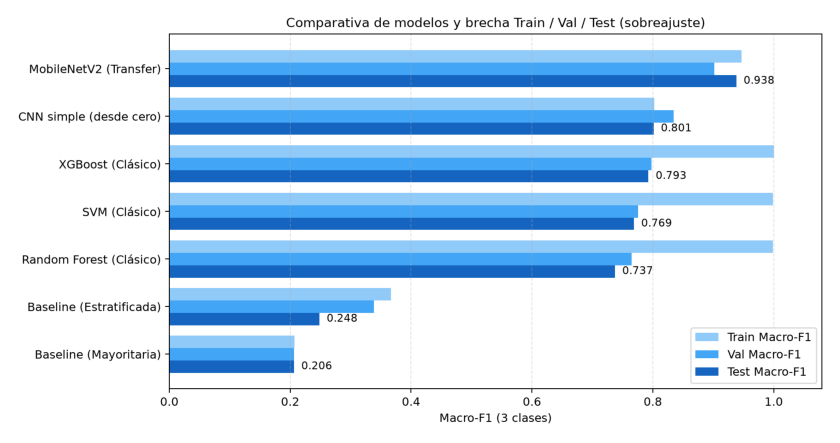

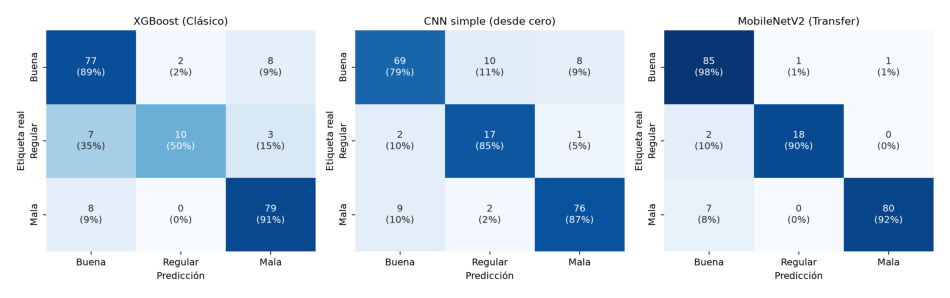

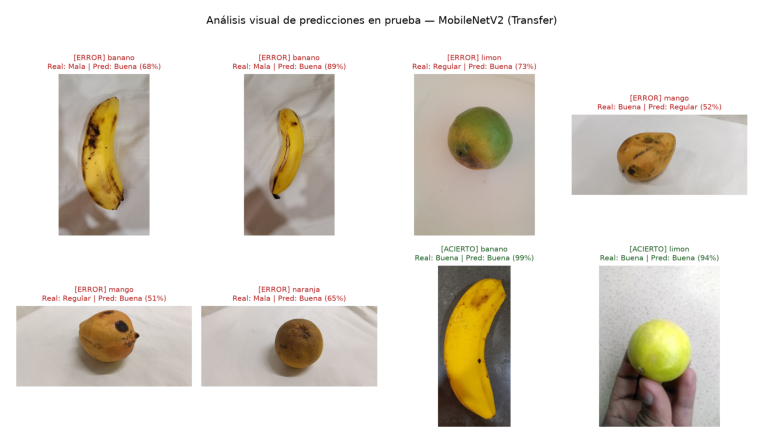

In [3]:
# Figuras clave: comparativa de modelos, matrices de confusión y análisis visual de errores
for stem in ("02_comparativa_modelos.png", "04_matrices_confusion.png", "05_analisis_errores_visual.png"):
    fig_path = DIR_FIGURAS / stem
    if fig_path.is_file():
        plt.figure(figsize=(12, 5.5))
        plt.imshow(Image.open(fig_path))
        plt.axis("off")
        plt.show()

Fórmula: max(bbox_width, bbox_height) / max(image_width, image_height)
La fórmula es invariante a giros de 90°, no a giros arbitrarios; la segmentación puede variar.
Referencias evaluadas: 204/204 | MAE=0.0124 | Mediana=0.0060 | RMSE=0.0192


,n,mae,median_ae,rmse
limon,45.0,0.01723,0.00955,0.02411
mango,43.0,0.00841,0.00426,0.01269
naranja,64.0,0.01569,0.00763,0.02360
tomate_arbol,52.0,0.00763,0.00464,0.01103



Cobertura de segmentación en el dataset combinado (971 imágenes):


,total,ok,failed,touches_border
FruitNet_Kaggle,580,580,0,419
FruitNet_Mixed_Segmentada,84,82,2,75
Propia,307,307,0,27


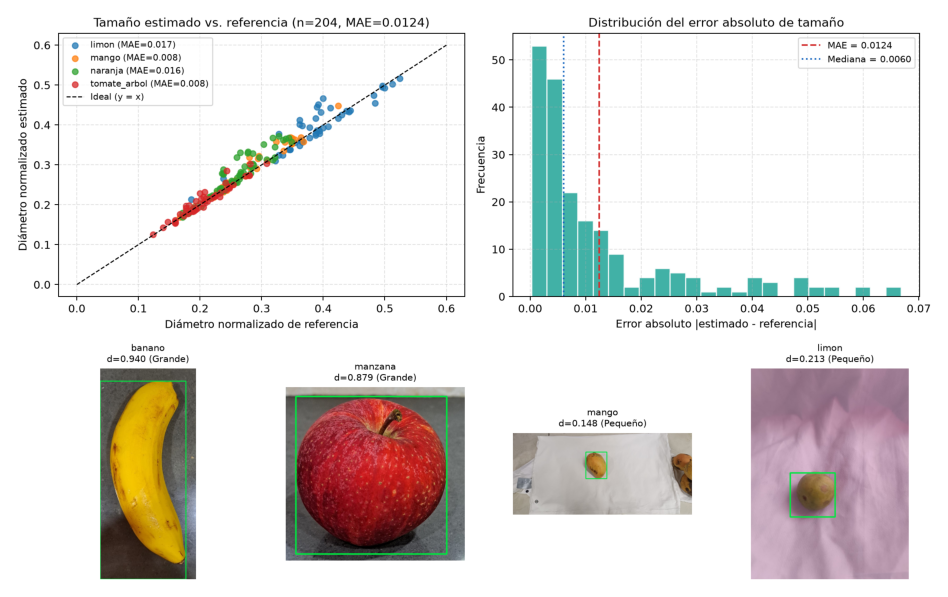

In [4]:
# Evaluación completa de estimación de tamaño (204 referencias + cobertura total en 971 fotos)
size_summary = report["size_evaluation"]
print(f"Fórmula: {size_summary['formula']}")
print("La fórmula es invariante a giros de 90°, no a giros arbitrarios; la segmentación puede variar.")
print(f"Referencias evaluadas: {size_summary['references_evaluated']}/{size_summary['references_total']} "
      f"| MAE={size_summary['mae']:.4f} | Mediana={size_summary['median_ae']:.4f} | RMSE={size_summary['rmse']:.4f}")
display(pd.DataFrame(size_summary["per_species"]).T)
print("\nCobertura de segmentación en el dataset combinado (971 imágenes):")
display(pd.DataFrame(size_summary["combined_dataset_coverage"]).T)

size_fig = DIR_FIGURAS / "06_evaluacion_tamano.png"
if size_fig.is_file():
    plt.figure(figsize=(12, 7.5))
    plt.imshow(Image.open(size_fig))
    plt.axis("off")
    plt.show()